# Scenes: material ground + material-filled objects

A scene composes the two lower levels:

1. a **material texture** as the ground;
2. semantic objects, themselves filled with materials.

Layouts use jittered positions and random orientations, so scenes carry
**no axis-aligned prior**. Each scene returns a `Scene` with the RGB image
and the placed objects (normalised bounding boxes).

Available scenes: `urban` (concrete ground), `forest` (soil ground) and
`fields` (grass ground).

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib import patches

from mlpsyn.scene import SCENES, generate_scene

import io


def check_figure_size(fig, max_mb=5.0):
    """Check that a figure's PNG stays below ``max_mb`` megabytes."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi)
    size_mb = buffer.getbuffer().nbytes / 1e6
    print(f"figure: {size_mb:.2f} MB")
    assert size_mb <= max_mb, f"figure too big: {size_mb:.2f} MB > {max_mb} MB"


### Visual analysis — 5 seeds per scene

Fourteen scene types, five seeds each.

- **urban** — warped streets with a connected road network; buildings are
  sized to fit between roads (no cross-road overlaps); blocks carry parks,
  parking lots (stalls + parked cars) and paved plazas (fountain/planting),
  plus buildings, trees, pools, cars and trucks.
- **forest** — soil ground with clustered stands, soft clearings, a track
  that follows gentle ground and a stream that follows the low ground of the
  shared elevation map.
- **fields** — irregular field mosaic: Voronoi parcels that tile the ground
  (no grass gaps), bounded by country roads / dirt tracks that give every
  field frontage, plus hedgerows, woodland blocks and a valley river; crop
  rows, one orchard block per scene, ponds, silos and trees.
- **coastal** — sandy shore with ripples, a wavy waterline with foam and a wet
  sand band, boats with wakes and rocks/scrub on land.
- **coastal_city** — a harbour waterfront: sea with a wavy shoreline and foam,
  a rubble **breakwater** out in the water, **piers** on pilings reaching into
  the sea, a sheltered **marina** with finger docks and rows of moored boats,
  plus a coast road, waterfront buildings, parking, cars and a park.
- **mountain** — rock ground with a Lambertian hillshade; snow sits on high
  ground, conifers on mid slopes, boulders on steep slopes and lakes in the
  lowest basins (all sampled from one elevation map).
- **arid** — sand with a **braided dry wadi**: a pale sandy apron, two or
  three gravel threads, scattered pebbles and no centre line (so it no longer
  reads as a road; rebuilt in Round 34), plus rock outcrops and sparse scrub.
- **scrubland** — dry sand/gravel ground with many boulders and scrub but **no
  trees**: a deliberate arid/mountain blend.
- **pasture** — rolling meadow with hedgerows, scattered trees, a farm track,
  a farmstead (buildings + silo) and ponds, over a soft relief overlay.
- **woodland_pasture** — a green meadow gone **half-woodland**: extensive tree
  clumps across the frame, so it is easily confused with `forest`
  (deliberately ambiguous).
- **wilderness** — dense, road-less canopy with a few clearings and a valley
  stream: a continuous forest mass rather than scattered trees.
- **savanna** — dry sandy/soil ground with many scattered trees and scrub:
  nearly forest-dense tree cover over arid ground (deliberately ambiguous).
- **forest_fields** — woodland and farmland side by side. The soil/grass
  boundary is a soft, mottled transition band; the farmland half is an
  irregular field mosaic with roads and hedges, not a rectangle grid.
- **urban_fringe** — city blocks next to fields, often split by a river. The
  concrete/grass boundary fades through a soft band, and the farmland half is
  an irregular road-bounded mosaic.

Diversity is good: scene type, composition, elevation-driven placement and
per-seed variation all change. The last four types are the intentionally
ambiguous ones used to harden the scene-classification notebook.


figure: 0.74 MB


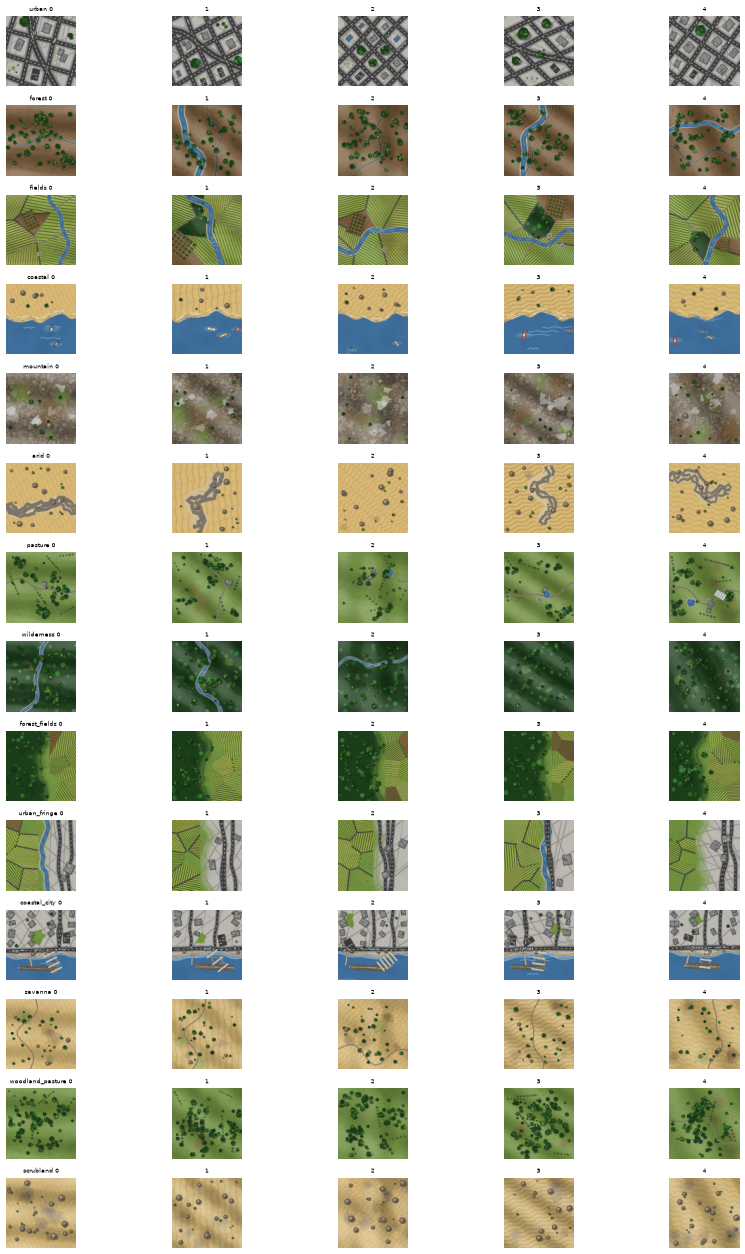

In [2]:
# Five instances per scene on a horizontal grid.
seeds = list(range(5))

fig, axes = plt.subplots(len(SCENES), len(seeds), figsize=(15, 1.5 * len(SCENES)), dpi=60)
for row, name in enumerate(SCENES):
    for col, seed in enumerate(seeds):
        scene = generate_scene(name, size=100, seed=seed)
        axes[row, col].imshow(scene.image)
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"{name} {seeds[0]}", fontsize=7)
    for col in range(1, len(seeds)):
        axes[row, col].set_title(f"{seeds[col]}", fontsize=7)
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — 5 seeds per scene

Ten scene types, five seeds each.

- **urban** — warped streets with a connected road network; buildings are
  sized to fit between roads (no cross-road overlaps); blocks carry parks,
  parking lots (stalls + parked cars) and paved plazas (fountain/planting),
  plus buildings, trees, pools, cars and trucks.
- **forest** — soil ground with clustered stands, soft clearings, a track
  that follows gentle ground and a stream that follows the low ground of the
  shared elevation map.
- **fields** — irregular field mosaic: Voronoi parcels that tile the ground
  (no grass gaps), bounded by country roads / dirt tracks that give every
  field frontage, plus hedgerows, woodland blocks and a valley river; crop
  rows, one orchard block per scene, ponds, silos and trees.
- **coastal** — sandy shore with ripples, a wavy waterline with foam and a wet
  sand band, boats with wakes and rocks/scrub on land.
- **mountain** — rock ground with a Lambertian hillshade; snow sits on high
  ground, conifers on mid slopes, boulders on steep slopes and lakes in the
  lowest basins (all sampled from one elevation map).
- **arid** — sand with a **braided dry wadi**: a pale sandy apron, two or
  three gravel threads, scattered pebbles and no centre line (so it no longer
  reads as a road; rebuilt in Round 34), plus rock outcrops and sparse scrub.
- **pasture** — rolling meadow with hedgerows, scattered trees, a farm track,
  a farmstead (buildings + silo) and ponds, over a soft relief overlay.
- **wilderness** — dense, road-less canopy with a few clearings and a valley
  stream: a continuous forest mass rather than scattered trees.
- **forest_fields** — woodland and farmland side by side. The soil/grass
  boundary is a soft, mottled transition band; the farmland half is an
  irregular field mosaic with roads and hedges, not a rectangle grid.
- **urban_fringe** — city blocks next to fields, often split by a river. The
  concrete/grass boundary fades through a soft band, and the farmland half is
  an irregular road-bounded mosaic.

Diversity is good: scene type, composition, elevation-driven placement and
per-seed variation all change.

- **coastal_city** — a harbour waterfront: sea with a wavy shoreline and foam,
  a rubble **breakwater** out in the water, **piers** on pilings reaching into
  the sea, a sheltered **marina** with finger docks and rows of moored boats,
  plus a coast road, waterfront buildings, parking, cars and a park.
- **forest_fields** — woodland (canopy fill + forest patches) on one side and a
  field mosaic that now reaches the top/bottom/right frame edges (no grass
  margin around the parcels).


figure: 0.43 MB


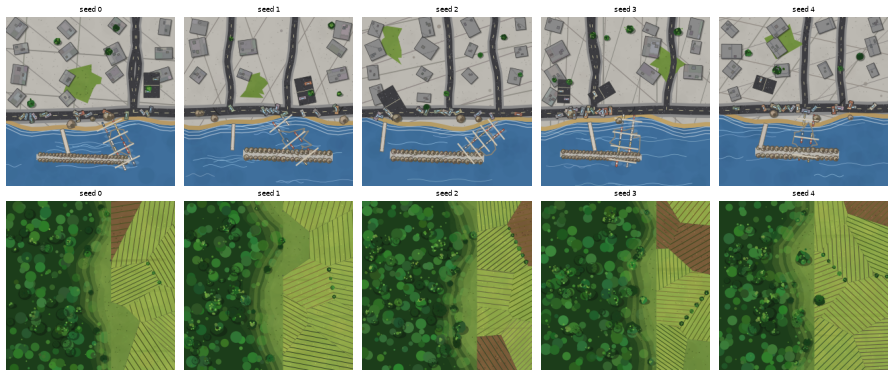

In [3]:
# Coastal city (breakwaters, piers, marinas) and the forest/field boundary.
seeds = list(range(5))
fig, axes = plt.subplots(2, len(seeds), figsize=(15, 6.4), dpi=60)
for col, seed in enumerate(seeds):
    axes[0, col].imshow(generate_scene("coastal_city", size=256, seed=seed).image)
    axes[1, col].imshow(generate_scene("forest_fields", size=256, seed=seed).image)
    axes[0, col].set_title(f"seed {seed}", fontsize=8)
    axes[1, col].set_title(f"seed {seed}", fontsize=8)
    axes[0, col].axis("off")
    axes[1, col].axis("off")
axes[0, 0].set_ylabel("coastal_city", fontsize=9)
axes[1, 0].set_ylabel("forest_fields", fontsize=9)
plt.tight_layout()
check_figure_size(fig)
plt.show()


### Visual analysis — coastal city and field boundaries

- **What I see (coastal_city):** the lower band is water with a wavy foam line and
  a wet-sand strip; a **rubble breakwater** (concrete core lined with boulders)
  runs parallel to the coast; one or two **piers** on pilings reach from the shore
  into the sea; a **marina** basin holds finger docks with rows of small moored
  boats; the land side has a coast road with cars, waterfront buildings, parking
  lots, trees and a green park.
- **Defects (coastal_city):** (1) the marina basin is water-filled with a quay
  edge but still reads close to the open sea; severity **low**. (2) some blocks
  remain plain concrete between buildings; severity **low**. (3) piers can point
  away from the marina rather than sheltering it; severity **low**.
- **Iteration:** buildings now sit on a jittered grid of blocks kept clear of the
  coast road and cross streets (no more loose slabs on the road), and the marina
  basin is water-filled with a quay edge.
- **What I see (forest_fields):** the left half is a dark forest canopy with
  clustered crowns; the right half is a field mosaic that **reaches the top,
  bottom and right image edges** — there is no grass/soil margin around the
  parcels anymore.
- **Defect fixed:** previously the field mosaic was inset by a 6 % margin and the
  woodland half was bare soil, so fields looked "surrounded by empty background".
  Now the mosaic box is the full frame and the woodland is filled with canopy.
- **Diversity across seeds:** the five seeds vary the shoreline phase, breakwater
  length/position, pier count and angle, marina position, building layout and the
  forest/field split, so the harbour is not a single fixed template.


## Object-level annotations

`Scene.objects` holds one `SceneObject` per placed object, with a
top-left-origin `pixel_bbox`.

figure: 0.26 MB


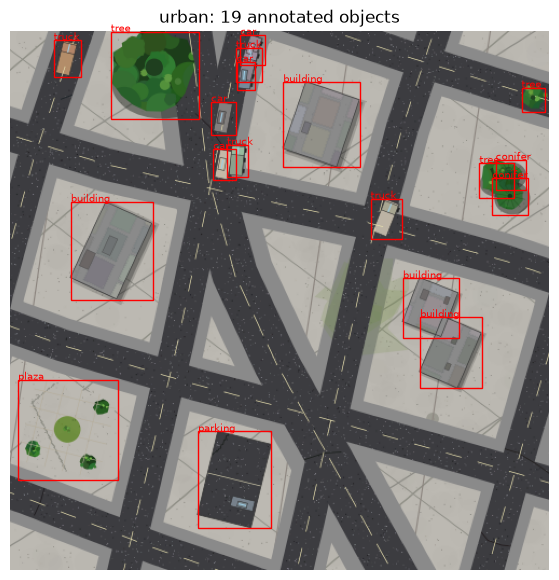

In [4]:
scene = generate_scene("urban", size=500, seed=0)

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(scene.image)
for obj in scene.objects:
    x0, y0, x1, y1 = obj.pixel_bbox(500)
    ax.add_patch(
        patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=1.0)
    )
    ax.text(x0, y0, obj.label, color="red", fontsize=7)
ax.set_title(f"urban: {len(scene.objects)} annotated objects")
ax.axis("off")
check_figure_size(fig)
plt.show()

### Visual analysis — object annotations

The 10 boxes align with the two trees and eight buildings. Boxes are
axis-aligned and clipped, and labels sit at the top-left corner. Roads, parks
and rivers are not annotated (only point objects are).

## Exporting annotations and splitting a dataset

`mlpsyn.annotations` converts `SceneObject`s to **COCO** (pixel boxes, top-left
origin) and **YOLO** (normalised boxes, top-left origin), and provides a
deterministic train/val/test split.

In [5]:
from mlpsyn.annotations import coco_dataset, train_val_test_split, yolo_lines

scenes = [
    generate_scene(name, size=160, seed=seed)
    for name, seed in [("urban", 0), ("fields", 1), ("pasture", 2)]
]
dataset = coco_dataset(scenes, 160)
print("COCO images:", len(dataset["images"]))
print("COCO categories:", [c["name"] for c in dataset["categories"]])
print("COCO annotations:", len(dataset["annotations"]))
print("sample bbox:", [round(v, 1) for v in dataset["annotations"][0]["bbox"]])
print("YOLO sample:", yolo_lines(scenes[0])[0])
split = train_val_test_split(20, seed=0)
print("split: train", len(split.train), "val", len(split.val), "test", len(split.test))

COCO images: 3
COCO categories: ['building', 'bush', 'car', 'conifer', 'field', 'hedgerow', 'orchard', 'parking', 'plaza', 'pond', 'silo', 'tree', 'truck']
COCO annotations: 86
sample bbox: [56.0, 119.0, 22.0, 28.0]
YOLO sample: 3 0.416213 0.832013 0.136935 0.178872
split: train 16 val 2 test 2


## Composition

Scenes are built from the object registry.

In [6]:
from collections import Counter

for name in SCENES:
    scene = generate_scene(name, size=300, seed=1)
    print(f"{name:8s} -> {dict(Counter(scene.labels()))}")

urban    -> {'tree': 4, 'parking': 2, 'building': 4, 'pool': 1, 'conifer': 1, 'truck': 1, 'car': 5}


forest   -> {'conifer': 18, 'bush': 8, 'tree': 21}


fields   -> {'field': 8, 'orchard': 1, 'conifer': 3, 'tree': 5, 'bush': 4, 'silo': 1}


coastal  -> {'boat': 3, 'rock': 3, 'bush': 2, 'tree': 1}


mountain -> {'conifer': 7, 'tree': 1, 'bush': 1, 'rock': 2}


arid     -> {'rock': 8, 'bush': 10}


... (4 outputs left out)

coastal_city -> {'breakwater': 1, 'pier': 1, 'boat': 12, 'marina': 1, 'building': 8, 'parking': 1, 'tree': 2, 'bush': 2, 'car': 12, 'rock': 4}


savanna  -> {'tree': 13, 'conifer': 11, 'bush': 10, 'rock': 4}


woodland_pasture -> {'tree': 32, 'bush': 18, 'conifer': 38, 'hedgerow': 7}


scrubland -> {'rock': 12, 'bush': 11}


## Grounds are materials

Each scene ground is a material texture, reused from the lowest level.

figure: 0.32 MB


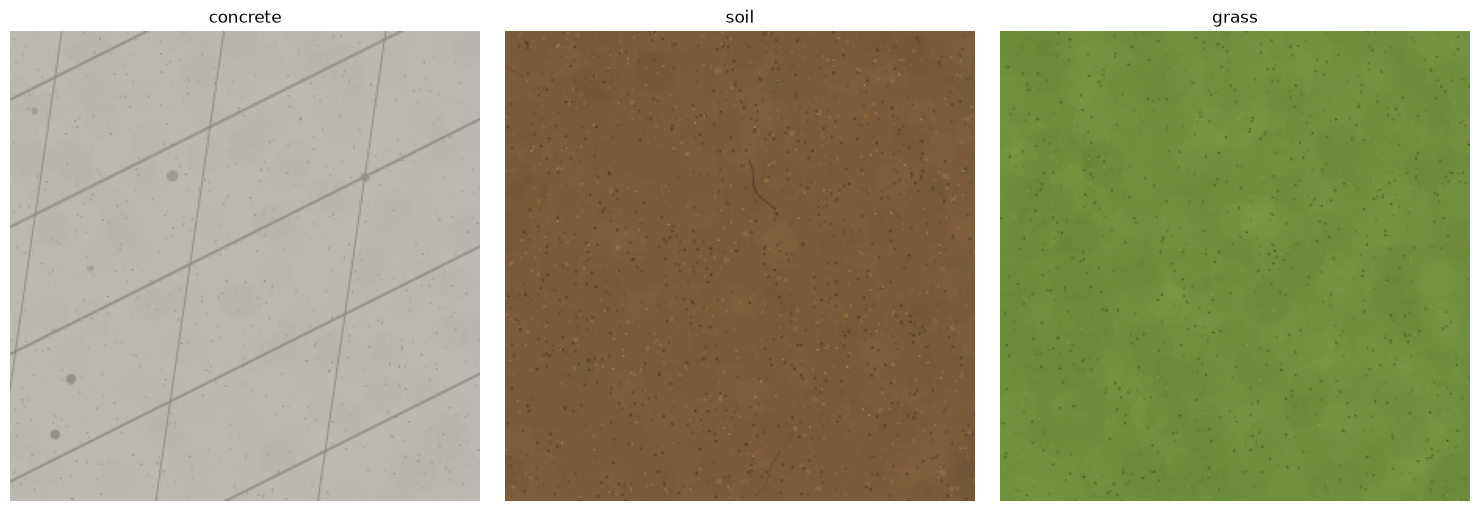

In [7]:
from mlpsyn.materials import MATERIALS

grounds = ["concrete", "soil", "grass"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, tex in zip(axes, grounds, strict=True):
    ax.imshow(MATERIALS[tex](size=300, seed=0))
    ax.set_title(tex)
    ax.axis("off")
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — grounds

Each scene ground is the matching material: `concrete` (urban), `soil` (forest)
and `grass` (fields). Grain is convincing: `concrete` shows expansion joints and
potholes, while `soil` and `grass` are grainy with subtle tonal patches.

## Land-cover backgrounds reuse the same materials

The `mlpsyn.satellite` land-cover backgrounds are built on the very same
materials: `agricultural_fields` uses a `soil` ground and fills its parcels
with `crop`/`soil` textures. They can be used as higher-level grounds when a
scene needs a pre-made land-cover pattern.

figure: 0.24 MB


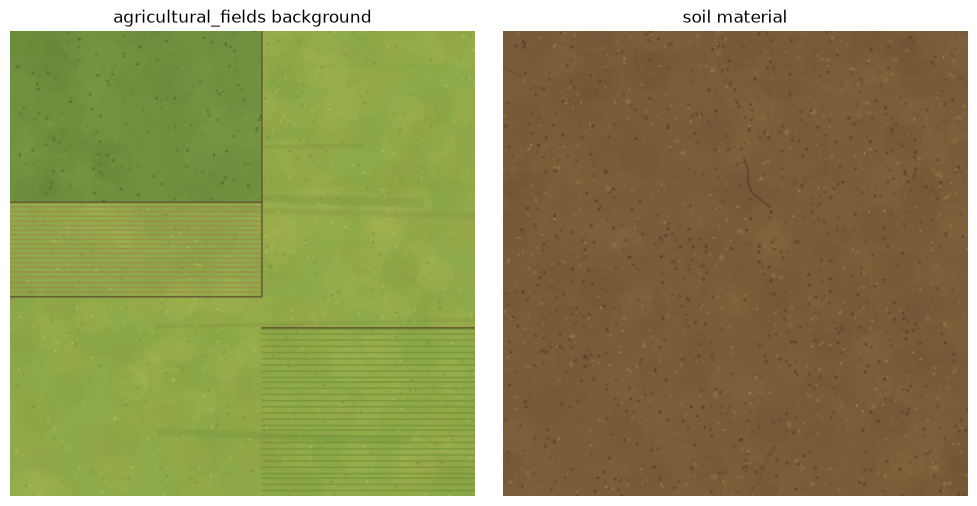

In [8]:
from mlpsyn.satellite import generate_satellite_texture

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(generate_satellite_texture("agricultural_fields", size=300, seed=0))
axes[0].set_title("agricultural_fields background")
axes[1].imshow(MATERIALS["soil"](size=300, seed=0))
axes[1].set_title("soil material")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — land-cover reuse

`agricultural_fields` is built on the same `soil`/`crop` materials: parcels with
crop-row striping and green/soil blocks. The parcel boundaries are axis-aligned
here (this is a background generator, not a composed scene) and the crop stripes
are clean. It matches the `soil` material shown on the right.

## Sensor and atmospheric effects

Rendered scenes can be degraded with Gaussian/Poisson sensor noise, optical blur, haze and cloud cover (see `mlpsyn.sensor`). Each effect is shown separately on the same scene for five seeds. In the composed pipeline, `apply_sensor` always applies the atmosphere (haze, clouds) *before* blur and noise.

figure: 0.46 MB


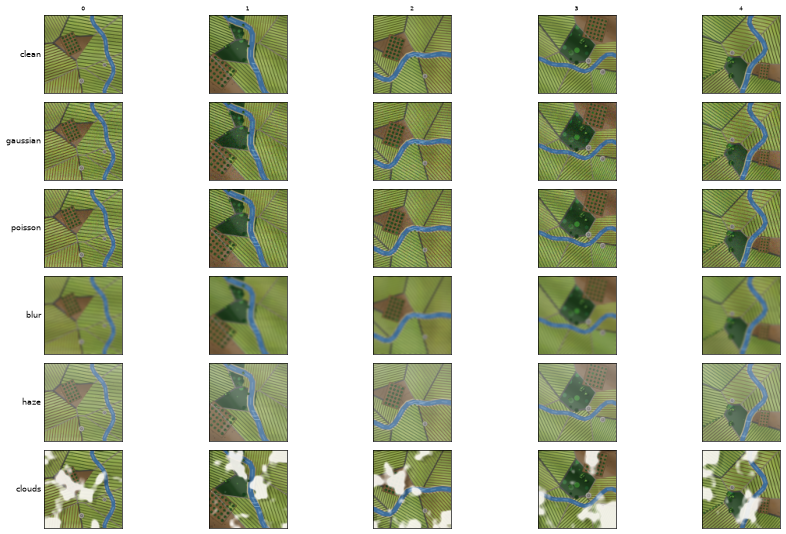

In [9]:
import numpy as np

from mlpsyn.sensor import EFFECTS

effects = list(EFFECTS)
base = {seed: generate_scene("fields", size=100, seed=seed).image for seed in seeds}

fig, axes = plt.subplots(len(effects), len(seeds), figsize=(15, 1.5 * len(effects)), dpi=60)
for row, effect in enumerate(effects):
    for col, seed in enumerate(seeds):
        rng = np.random.default_rng(seed)
        axes[row, col].imshow(EFFECTS[effect](base[seed], rng))
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if row == 0:
            axes[row, col].set_title(f"{seed}", fontsize=7)
    axes[row, 0].set_ylabel(effect, fontsize=9, rotation=0, ha="right", va="center")
plt.tight_layout()
check_figure_size(fig)
plt.show()

### Visual analysis — sensor and atmospheric effects

- **clean** — reference, no degradation.
- **gaussian** — per-pixel read noise; plausible for a low-light sensor.
- **poisson** — strong shot noise, most visible in dark areas.
- **blur** — optical blur; edges soften.
- **haze** — the scene washes toward a pale sky colour, stronger at the top.
- **clouds** — large semi-transparent cloud masses with an offset ground shadow,
  covering roughly 40% of the frame.

All five seeds behave consistently; the degradation is independent of the scene
seed. (Vignette and JPEG were removed as they are camera artefacts, not
satellite effects.)

## Determinism

Same seed, same image and same annotations.

In [10]:
a = generate_scene("fields", size=256, seed=42)
b = generate_scene("fields", size=256, seed=42)
print("same image:", (a.image == b.image).all())
print("same objects:", a.objects == b.objects)

same image: True
same objects: True
